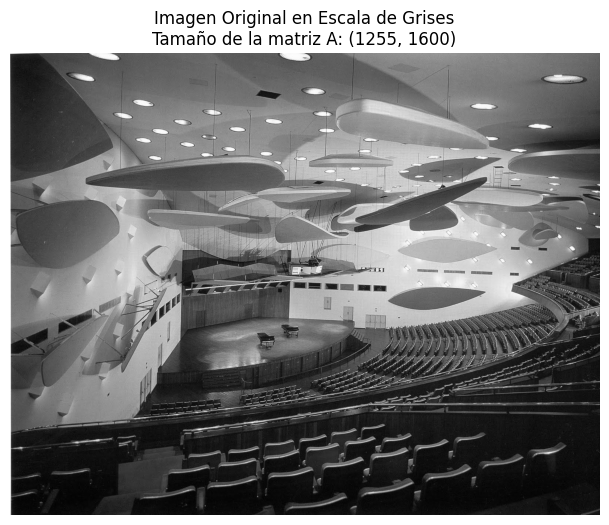

SVD calculada
Dimensiones de U: (1255, 1255)
Dimensiones de S (Valores singulares): (1255,)
Dimensiones de V^T: (1600, 1600)
------------------------------


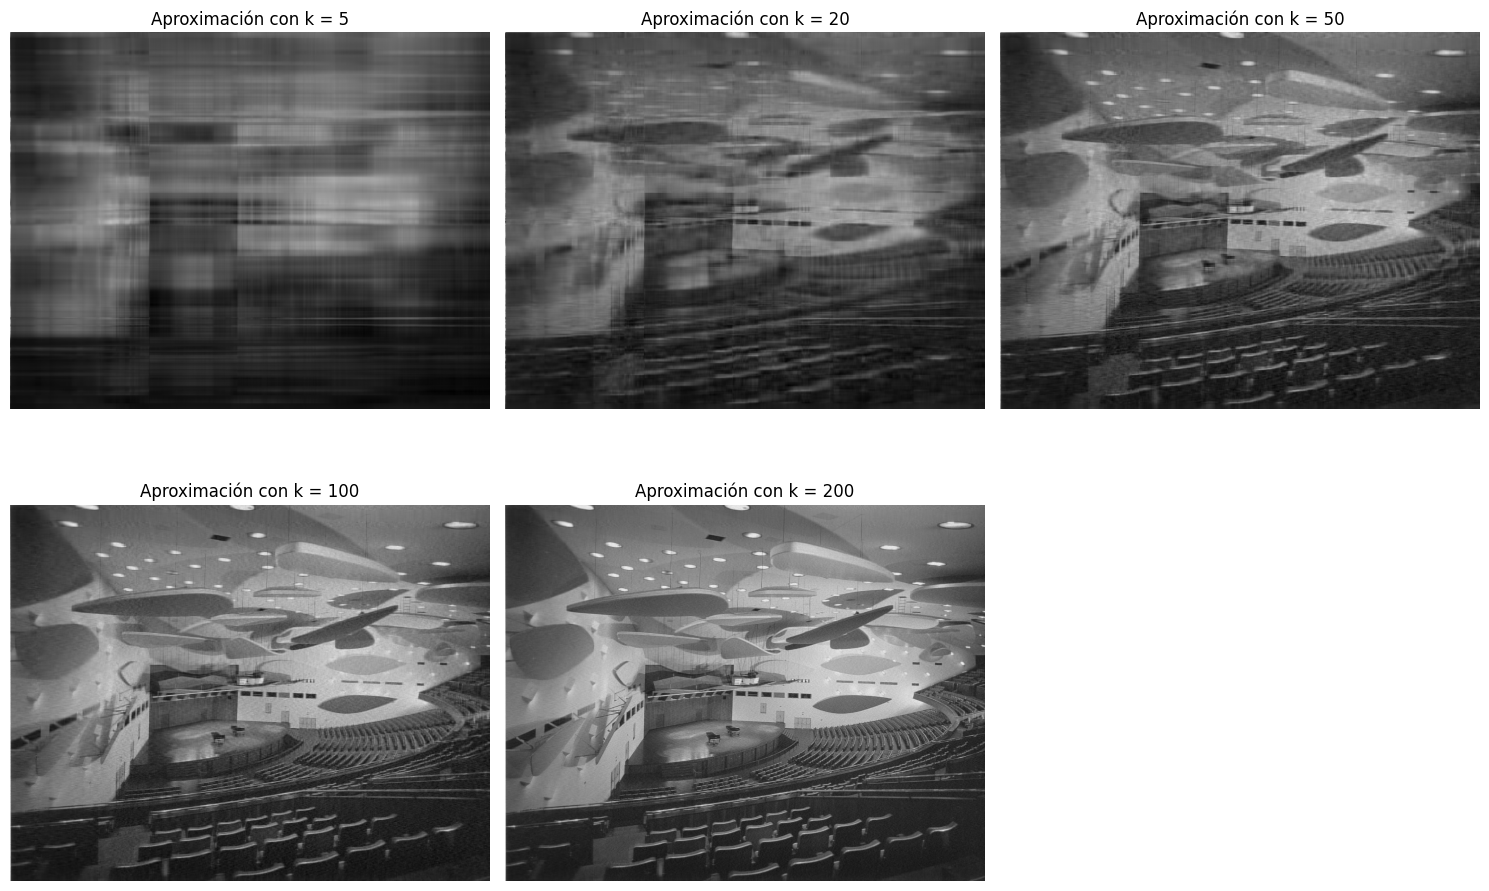

------------------------------


,Valores de k,Relación de Almacenamiento,Error Relativo,Energía Capturada
0,5,0.007112,0.266014,0.929236
1,20,0.028446,0.188465,0.964481
2,50,0.071116,0.143358,0.979448
3,100,0.142231,0.109983,0.987904
4,200,0.284462,0.076198,0.994194


------------------------------


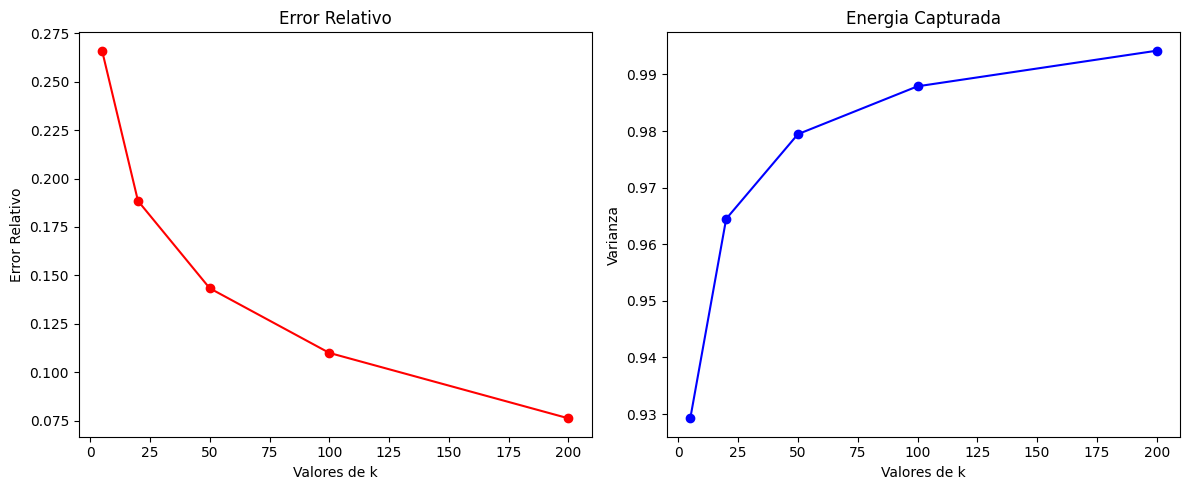

------------------------------


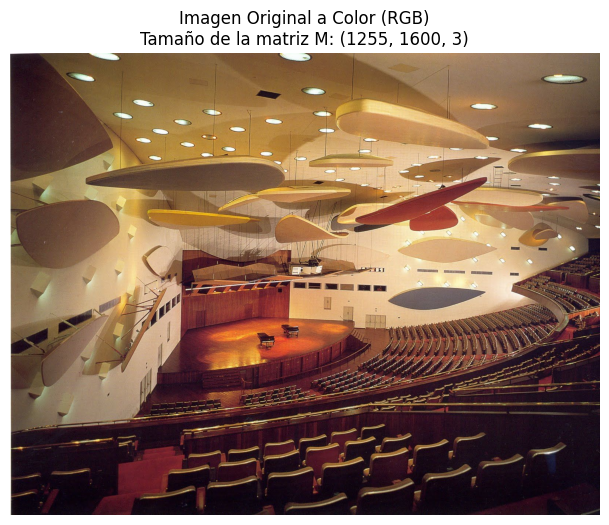

------------------------------


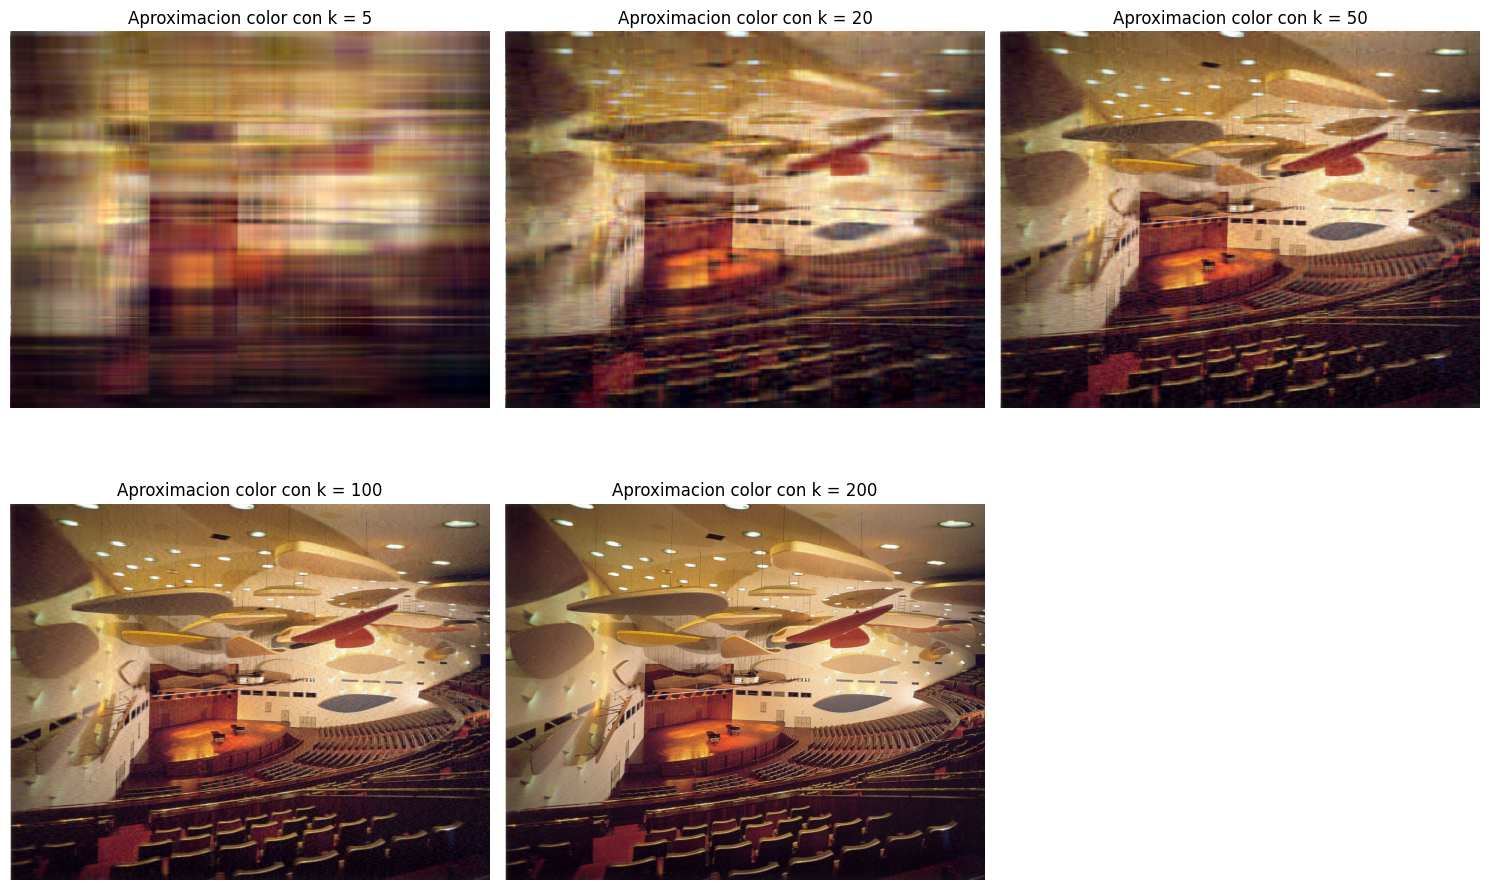

------------------------------


,Valores de k,Relacion de Almacenamiento,Error Relativo,Energia Capturada
0,5,0.007112,0.266777,0.928713
1,20,0.028446,0.188927,0.964174
2,50,0.071116,0.143936,0.979209
3,100,0.142231,0.111019,0.987632
4,200,0.284462,0.077236,0.994014


------------------------------


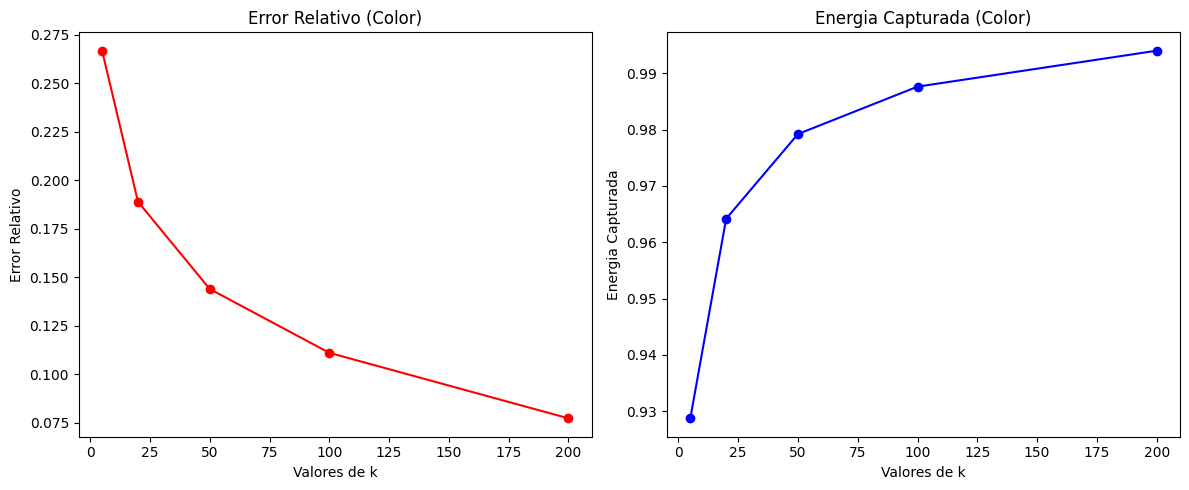

------------------------------


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

# Cargar la imagen
ruta_imagen = 'aula_magna.jpg'
img_color = Image.open(ruta_imagen)

# Convertir a escala de grises L es luminiscencia
img_gris = img_color.convert('L')

# Convertir a una matriz, float para evitar errores
A = np.array(img_gris, dtype=float)

# Visualizar la matriz
plt.figure(figsize=(8, 6))
plt.imshow(A, cmap='gray')
plt.title(f"Imagen Original en Escala de Grises\nTamaño de la matriz A: {A.shape}")
plt.axis('off')
plt.savefig('img_gris.png', dpi=300, bbox_inches='tight')
plt.show()

# Calcular la SVD de la matriz
U, S, VT = np.linalg.svd(A)

print("SVD calculada")
print(f"Dimensiones de U: {U.shape}")
print(f"Dimensiones de S (Valores singulares): {S.shape}")
print(f"Dimensiones de V^T: {VT.shape}")
print("-" * 30)

# aproximaciones A_k
k_valores = [5, 20, 50, 100, 200]

# figura grande para mostrar las imágenes
plt.figure(figsize=(15, 10))

# variables que se usarán en el análisis cuantitativo posterior
m, n = A.shape

# Calculamos la suma total de los valores singulares al cuadrado que irá en el denominador de la energía
# S ya contiene los valores singulares asi que los elevamos al cuadrado y sumamos
energia_total = np.sum(S**2)
norma_frobenius_A = np.linalg.norm(A, 'fro')
lista_errores = []
lista_energia = []
lista_tasas = []
# Se van a calcular estos elementos en el bucle for de abajo para mayor eficiencia


# Visualizar las reconstrucciones
for i, k in enumerate(k_valores):
    # Tomamos las primeras 'k' columnas de U, 'k' valores de S, y 'k' filas de VT
    U_k = U[:, :k] # valores singulares izquierdos, son los patrones verticales de la imagen
    S_k = np.diag(S[:k]) # Convertimos el vector 1D en una matriz diagonal, la funcion svd devuelve S como un vector, por eso lo pasamos a diagonal con los valores que queremos, S contiene la importancia de cada patron ordenados de mas importante a menos importante
    VT_k = VT[:k, :] # valores singulares derechos, son los patrones horizontales de la imagen

    # Multiplicación de matrices: A_k = U_k * S_k * VT_k
    A_k = np.dot(U_k, np.dot(S_k, VT_k))

    # Cálculo de las tasas de compresion
    lista_tasas.append(k * (m + n + 1) / (m * n))

    # Cálculo de los errores relativos para cada k
    lista_errores.append(np.linalg.norm(A - A_k, 'fro') / norma_frobenius_A)

    # Cálculo de las energías
    lista_energia.append(np.sum(S[:k]**2) / energia_total)

    # Añadimos la imagen a la cuadrícula
    plt.subplot(2, 3, i + 1)
    plt.imshow(A_k, cmap='gray')
    plt.title(f"Aproximación con k = {k}")
    plt.axis('off')

plt.tight_layout()
plt.savefig('aproximaciones.png', dpi=300, bbox_inches='tight')
plt.show()

# Análisis cuantitativo

tabla_resultados = {
    'Valores de k': k_valores,
    'Relación de Almacenamiento': lista_tasas,
    'Error Relativo': lista_errores,
    'Energía Capturada': lista_energia
}
df_resultados = pd.DataFrame(tabla_resultados)
print("-" * 30)
display(df_resultados)
print("-" * 30)
plt.figure(figsize=(12,5))

# grafica del error relativo
plt.subplot(1, 2, 1)
plt.plot(k_valores, lista_errores, color='red', marker='o')
plt.title('Error Relativo')
plt.xlabel('Valores de k')
plt.ylabel('Error Relativo')

# grafica de la energia
plt.subplot(1, 2, 2)
plt.plot(k_valores, lista_energia, color='blue', marker='o')
plt.title('Energia Capturada')
plt.xlabel('Valores de k')
plt.ylabel('Varianza')

plt.tight_layout()
plt.savefig('analisis.png', dpi=300, bbox_inches='tight')
plt.show()
print("-" * 30)

# Tratamiento de una imagen a color

M = np.array(img_color, dtype=float) # como es a color tenemos un tensor (mxnx3)
# La svd es para matrices en 2d así que hay que descomponer nuestra matriz tridimensional en 3 canales
R = M[:, :, 0]
G = M[:, :, 1]
B = M[:, :, 2]

plt.figure(figsize=(8, 6))
plt.imshow(np.clip(M, 0, 255).astype(np.uint8))
plt.title(f"Imagen Original a Color (RGB)\nTamaño de la matriz M: {M.shape}")
plt.axis('off')
plt.savefig('img_color.png', dpi=300, bbox_inches='tight')
plt.show()
print("-" * 30)

# Cálculo de la svd para cada matriz
U_R, S_R, VT_R = np.linalg.svd(R, full_matrices=False)
U_G, S_G, VT_G = np.linalg.svd(G, full_matrices=False)
U_B, S_B, VT_B = np.linalg.svd(B, full_matrices=False)

energia_total_color = np.sum(S_R**2) + np.sum(S_G**2) + np.sum(S_B**2) # energia total tomando en cuenta todos los canales
norma_frobenius_M = np.linalg.norm(M.ravel()) # ravel() es para tomar en cuenta los 3 canales
lista_tasas_color = []
lista_errores_color = []
lista_energia_color = []
m_color, n_color, c = M.shape

# Cálculo de la compresión por cada canal rgb
plt.figure(figsize=(15, 10))
for i, k in enumerate(k_valores):

    # Reconstruccion de la matriz original para cada k valor
    # Canal Rojo
    U_r_k = U_R[:, :k]
    S_r_k = np.diag(S_R[:k])
    VT_r_k = VT_R[:k, :]
    # Canal Verde
    U_g_k = U_G[:, :k]
    S_g_k = np.diag(S_G[:k])
    VT_g_k = VT_G[:k, :]
    # Canal Azul
    U_b_k = U_B[:, :k]
    S_b_k = np.diag(S_B[:k])
    VT_b_k = VT_B[:k, :]

    # Multiplicación de matrices
    # Canal Rojo
    R_k = np.dot(U_r_k, np.dot(S_r_k, VT_r_k))
    # Canal Verde
    G_k = np.dot(U_g_k, np.dot(S_g_k, VT_g_k))
    # Canal Azul
    B_k = np.dot(U_b_k, np.dot(S_b_k, VT_b_k))

    # Combinación de los canales
    M_k = np.stack((R_k, G_k, B_k), axis=2) # reconstruye la matriz 3d
    M_k = np.clip(M_k, 0, 255) # cualquier valor negativo se trunca a 0 y cualquier mayor a 255 se trunca a 255

    # Cáculo de las tasas de compresion
    lista_tasas_color.append(k * (m_color + n_color + 1) / (m_color * n_color))

    # Cálculo de los errores relativos con su 3d y todo
    lista_errores_color.append(np.linalg.norm((M - M_k).ravel()) / norma_frobenius_M)

    # Energia capturada global sumando energia por canal
    energia_k = (np.sum(S_R[:k]**2) + np.sum(S_G[:k]**2) + np.sum(S_B[:k]**2)) / energia_total_color
    lista_energia_color.append(energia_k)

    # Aquí paso los float de la matriz a color a unos enteros unsigned del 0 a 255
    M_vis = M_k.astype(np.uint8) # es nada mas para visualizar sin errores o cualquier cosa rara

    plt.subplot(2, 3, i + 1)
    plt.imshow(M_vis)
    plt.title(f"Aproximacion color con k = {k}")
    plt.axis('off')

plt.tight_layout()
plt.savefig('aproximaciones_color.png', dpi=300, bbox_inches='tight')
plt.show()

# Analisis cuantitativo en color

tabla_resultados_color = {
    'Valores de k': k_valores,
    'Relacion de Almacenamiento': lista_tasas_color,
    'Error Relativo': lista_errores_color,
    'Energia Capturada': lista_energia_color
}

df_resultados_color = pd.DataFrame(tabla_resultados_color)
print("-" * 30)
display(df_resultados_color)
print("-" * 30)

plt.figure(figsize=(12, 5))

# grafica del error relativo
plt.subplot(1, 2, 1)
plt.plot(k_valores, lista_errores_color, color='red', marker='o')
plt.title('Error Relativo (Color)')
plt.xlabel('Valores de k')
plt.ylabel('Error Relativo')

# grafica de la energia capturada
plt.subplot(1, 2, 2)
plt.plot(k_valores, lista_energia_color, color='blue', marker='o')
plt.title('Energia Capturada (Color)')
plt.xlabel('Valores de k')
plt.ylabel('Energia Capturada')

plt.tight_layout()
plt.savefig('analisis_color.png', dpi=300, bbox_inches='tight')
plt.show()
print("-" * 30)